# Hydroformylation greedy NMPC — state-space surrogates with Gurobi

This notebook is a **worked example** of building a one-step **transition surrogate**
of a stiff chemical reactor and *optimizing through* it with Gurobi. The reactor
dynamics and the **known optimal control profile have already been computed** and saved
to `datasets/ms_15s_optimal.npz` (a 70-minute, 15-second single-shooting solve of the
true kinetic ODE: `T` ramps 368.15 K -> 388.15 K while `u` holds the total pressure on
the 20 bar active constraint). **We do not re-solve for the optimum here** — we *generate
training data around it* and ask three surrogate formulations to recover good control
online.

> **Solver.** Every optimization in this notebook is solved with **Gurobi**
> (`gurobi` / `gurobi_persistent`). All three surrogate embeddings reduce to a
> mixed-integer linear program; we standardise on Gurobi throughout.

**What changed — a state-space training recipe.** Earlier versions perturbed the whole
control *profile* and rolled catalyst-drift *trajectories*. This version is **state-centric**:

1. Every state on the **known optimal trajectory** is taken as an anchor — its
   concentrations and partial pressures.
2. The training **data points are scattered around the state space** in a local
   neighbourhood of each anchor, and one true-plant step is taken from each sampled
   `(state, T, u)`.
3. The surrogate **targets** are exactly what the controller needs: the **resulting
   partial pressures in the next step** `(p_H2', p_CO')` — so the 20-bar constraint can
   be enforced — and the **change of the desired compound** `Δ nC13al` — the objective.
4. The **catalyst activation rate `gamma` is NOT varied**: a single nominal plant
   generates all data.

Because the plant ODE is autonomous (the right-hand side depends only on the state and
the controls), **time is not a feature** — the surrogate is a pure state→next-output map
`(state(9), T, u) → (p_H2', p_CO', Δ nC13al)`.

**What we build:**
1. A **state-space transition dataset** (scattered around the optimal states), visualised
   in state space with a **k-nearest-neighbours** view of representative states.
2. Three surrogates trained with the source code — a **tanh** net, a **ReLU** net and an
   exact-**PWL** net (13-segment piecewise-linear `tanh`, dense near the origin).
3. A closed-loop **10-minute greedy** controller that, at each 15-second step, solves a
   single-block MILP for the `(T, u)` maximising the next-step `nC13al` subject to the
   reconstructed 20-bar pressure limit.


In [4]:
from __future__ import annotations

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.simplefilter("ignore")

# --- locate the project root and put src/ on the path -----------------
ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "pyproject.toml").exists() and (candidate / "src" / "pwlnet").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not find the PWLNet project root.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import pyomo.environ as pyo

# --- scikit-learn: state-space visualisation + k-nearest-neighbours ----
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

# === pwlnet source API used in this example ===========================
from pwlnet import PWLNet                                   # facade: train
from pwlnet.processes.hydroformylation import (             # the reactor benchmark
    CONTROL_BOUNDS, IDX, INITIAL_STATE, PLOT_COMPOUND_NAMES,
    STATE_BOUNDS, STATE_NAMES, T_FINAL, HydroformylationParameters,
    step_state, tighten_network_bounds,
)
from pwlnet.formulations.omlt import build_omlt_block             # ReLU big-M embedding
from pwlnet.formulations.pyomo_pwl import build_tanh_pwl_bigm_block   # PWL-tanh embedding
from pwlnet.formulations.pyomo_pwl.breakpoints import get_tanh_breakpoints
from pwlnet.solvers.solver_config import get_milp_solver    # configured solver factory

plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(2479085)

# --- confirm Gurobi is the active solver, once, up front --------------
_g = get_milp_solver("gurobi", options={"OutputFlag": 0})
print("Gurobi available:", bool(_g.available(exception_flag=False)))

nS = len(STATE_NAMES)
DT = 0.25                       # 15-second decision interval, in minutes
T_LO, T_HI = CONTROL_BOUNDS[0]  # temperature bounds [K]
U_LO, U_HI = CONTROL_BOUNDS[1]  # gas-feed bounds [mol/min]
MAX_P = 20.0                    # maximum total pressure [bar]
print(f"states={nS}  dt={DT*60:.0f}s  T in [{T_LO},{T_HI}] K  u in [{U_LO},{U_HI}] mol/min  Pmax={MAX_P} bar")


Gurobi available: True
states=9  dt=15s  T in [368.15,388.15] K  u in [0.0,7.0] mol/min  Pmax=20.0 bar


## Problem definition

The plant is a semi-batch hydroformylation reactor (Hentschel-aligned kinetics).
The state vector is

$$x = [\,c_{H_2},\,c_{CO},\,nC12en,\,iC12en,\,nC13al,\,nC12an,\,iC13al,\,p_{H_2},\,p_{CO}\,]$$

(liquid concentrations in mol/L, gas partial pressures in bar). The **manipulated
inputs** are the reactor temperature `T` and the synthesis-gas feed rate `u`. The
**objective** is to maximize the terminal concentration of the desired product
**`nC13al`** (the linear aldehyde).

**Constraints** — exactly as requested, *no back-off term*:

| quantity | constraint |
|---|---|
| temperature | $368.15 \le T \le 388.15$ K |
| total pressure | $p_{H_2} + p_{CO} \le 20$ bar |
| gas feed | $0 \le u \le 7$ mol/min |

The pressure limit is imposed softly through a heavily-penalised slack so the MILP
is always feasible (the initial state already sits at 20 bar); the slack is zero
whenever the limit can be met.


known optimal: 280 steps, terminal nC13al = 0.5755
T* range [368.15, 388.15] K   u* range [0.001, 0.485] mol/min


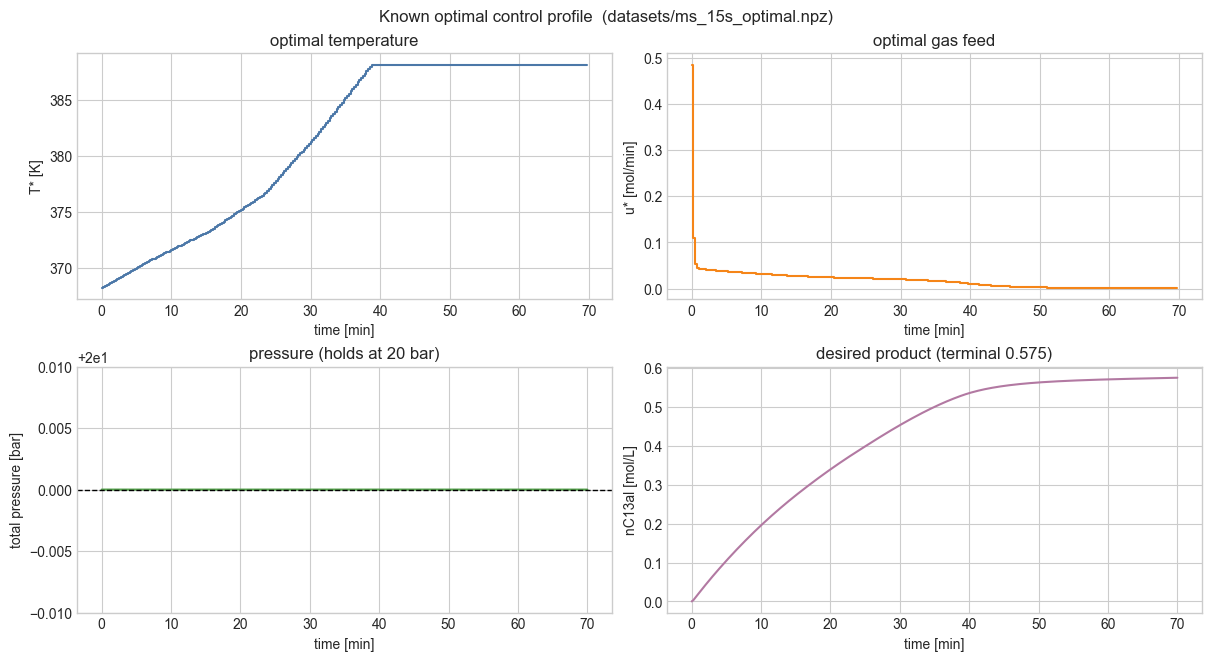

In [5]:
# === USAGE: load the *known* optimal (we do NOT recompute it) =========
# 15 s resolution, 70 min, u recovered from the active 20 bar pressure
# constraint, T optimized (368.15 K -> ramp -> 388.15 K). See
# experiments/Hydroformulation_ms_benchmark_solver/solve_15s_optimal.py
opt = np.load(ROOT / "datasets" / "ms_15s_optimal.npz")
T_star, u_star = opt["T"], opt["u"]            # 280 decisions at 15 s over 70 min
opt_states, opt_times = opt["states"], opt["times"]
opt_p = opt_states[:, IDX["p_H2"]] + opt_states[:, IDX["p_CO"]]
OPT_TERMINAL = float(opt_states[-1, IDX["nC13al"]])
print(f"known optimal: {len(T_star)} steps, terminal nC13al = {OPT_TERMINAL:.4f}")
print(f"T* range [{T_star.min():.2f}, {T_star.max():.2f}] K   "
      f"u* range [{u_star.min():.3f}, {u_star.max():.3f}] mol/min")

fig, ax = plt.subplots(2, 2, figsize=(12, 6.5), constrained_layout=True)
ax[0, 0].step(opt_times[:-1], T_star, where="post", color="#4c78a8"); ax[0, 0].set(ylabel="T* [K]", xlabel="time [min]", title="optimal temperature")
ax[0, 1].step(opt_times[:-1], u_star, where="post", color="#f58518"); ax[0, 1].set(ylabel="u* [mol/min]", xlabel="time [min]", title="optimal gas feed")
ax[1, 0].plot(opt_times, opt_p, color="#54a24b"); ax[1, 0].axhline(MAX_P, ls="--", color="k", lw=1)
ax[1, 0].set(ylabel="total pressure [bar]", xlabel="time [min]", title="pressure (holds at 20 bar)")
ax[1, 0].set_ylim(-1e-2+2e1,1e-2+2e1)
ax[1, 1].plot(opt_times, opt_states[:, IDX["nC13al"]], color="#b279a2")
ax[1, 1].set(ylabel="nC13al [mol/L]", xlabel="time [min]", title=f"desired product (terminal {OPT_TERMINAL:.3f})")
fig.suptitle("Known optimal control profile  (datasets/ms_15s_optimal.npz)")
plt.show()


## Dataset: state-space transitions sampled around the optimum

The surrogate learns a one-step map from the **state and controls** to the two quantities
the controller actually needs:

$$\big(p_{H_2}',\; p_{CO}',\; \Delta nC13al\big)\;=\;g\big(x,\,T,\,u\big)$$

where $p_{H_2}', p_{CO}'$ are the **partial pressures in the next step** (their sum is the
constrained total pressure) and $\Delta nC13al = nC13al' - nC13al$ is the **change of the
desired compound**. Three design choices follow the request:

* **anchor on the optimal states** — every state $x^*_k$ on the saved optimal trajectory
  (its concentrations and partial pressures) is used as an anchor.
* **scatter the data points in the state space** — instead of perturbing a whole control
  profile and rolling a trajectory, each anchor is surrounded by an independent cloud of
  sampled states; the controls are perturbed around $(T^*_k, u^*_k)$ with occasional
  high-feed probes so the surrogate sees the pressure constraint becoming active.
* **no catalyst drift** — the catalyst activation rate `gamma` is **fixed at the nominal
  value** for every sample. A single true plant generates all targets.

Each sampled $(x, T, u)$ takes **one true stiff-ODE step** to produce $x'$, from which the
two next-step partial pressures and the product change are recorded. Time is **not** a
feature: the plant is autonomous, so the state alone fixes the dynamics.


In [6]:
# === USAGE: state-space transition dataset (annotated) ================
PROD = IDX["nC13al"]                   # desired compound (Δ target)
P_H2, P_CO = IDX["p_H2"], IDX["p_CO"]  # next-step partial pressures (absolute targets)
N_IN, N_OUT = nS + 2, 3                # 11 inputs (state + T + u), 3 outputs

# per-state scatter width: a fraction of each state's span along the optimum,
# with an explicit (larger) spread on the two partial pressures so the surrogate
# sees the constraint region clearly.
_state_span = opt_states.max(axis=0) - opt_states.min(axis=0)


def make_dataset(n_per, rng, *, sigma_state_frac=0.08, sigma_p=0.6,
                 sigma_T=4.0, sigma_log_u=0.5, high_feed_frac=0.30):
    # Scatter samples around every optimal state, take ONE true step from each, and
    # record [state(9), T, u] -> [p_H2', p_CO', Δ nC13al]. gamma is NEVER varied.
    plant = HydroformylationParameters()                 # nominal catalyst, gamma = 1
    sigma_state = sigma_state_frac * _state_span + 1e-6
    sigma_state[P_H2] = sigma_p
    sigma_state[P_CO] = sigma_p
    rows_x, rows_y, samp_states = [], [], []
    for k in range(len(u_star)):                          # every optimal-state anchor
        x_star = opt_states[k].astype(float)
        for _ in range(n_per):
            # scatter the data point around the anchor state ...
            x = np.clip(x_star + rng.normal(0.0, sigma_state),
                        STATE_BOUNDS[:, 0], STATE_BOUNDS[:, 1])
            # ... and perturb the controls around the optimal (high-feed probes too)
            T = float(np.clip(T_star[k] + rng.normal(0.0, sigma_T), T_LO, T_HI))
            # multiplicative: u* spans 0.0009-0.49 mol/min along the optimum, so one
            # additive sigma is invisible at the opening feed and clips the tail to 0
            u = float(np.clip(u_star[k] * np.exp(rng.normal(0.0, sigma_log_u)),
                              U_LO, U_HI))
            if rng.random() < high_feed_frac:
                u = float(np.clip(u + rng.uniform(0.5, 4.0), U_LO, U_HI))  # push pressure up
            x_next = step_state(x, T, u, DT, plant)       # one true stiff-ODE step
            rows_x.append(np.r_[x, T, u])
            rows_y.append([x_next[P_H2], x_next[P_CO], x_next[PROD] - x[PROD]])
            samp_states.append(x.copy())
    return np.asarray(rows_x), np.asarray(rows_y), np.asarray(samp_states)


t0 = time.perf_counter()
X, Y, samp_states = make_dataset(16, rng)          # 16 samples per optimal state
gen_seconds = time.perf_counter() - t0

# train / validation / test split
perm = rng.permutation(len(X))
n_tr, n_va = int(0.70 * len(X)), int(0.15 * len(X))
i_tr, i_va, i_te = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
Xtr, Ytr = X[i_tr], Y[i_tr]
Xva, Yva = X[i_va], Y[i_va]
Xte, Yte = X[i_te], Y[i_te]
print(f"generated {len(X)} state-space transitions in {gen_seconds:.1f}s   "
      f"split = {len(Xtr)} train / {len(Xva)} val / {len(Xte)} test")
print(f"inputs={N_IN} (state {nS} + T + u)   outputs={N_OUT} (p_H2', p_CO', Δ nC13al)")
print(f"Δ-nC13al per step: mean {Y[:, 2].mean():.4f}  max {Y[:, 2].max():.4f}   "
      f"next total pressure: mean {(Y[:, 0] + Y[:, 1]).mean():.2f}  max {(Y[:, 0] + Y[:, 1]).max():.2f} bar")


generated 4480 state-space transitions in 35.5s   split = 3136 train / 672 val / 672 test
inputs=11 (state 9 + T + u)   outputs=3 (p_H2', p_CO', Δ nC13al)
Δ-nC13al per step: mean 0.0025  max 0.0161   next total pressure: mean 25.37  max 52.50 bar


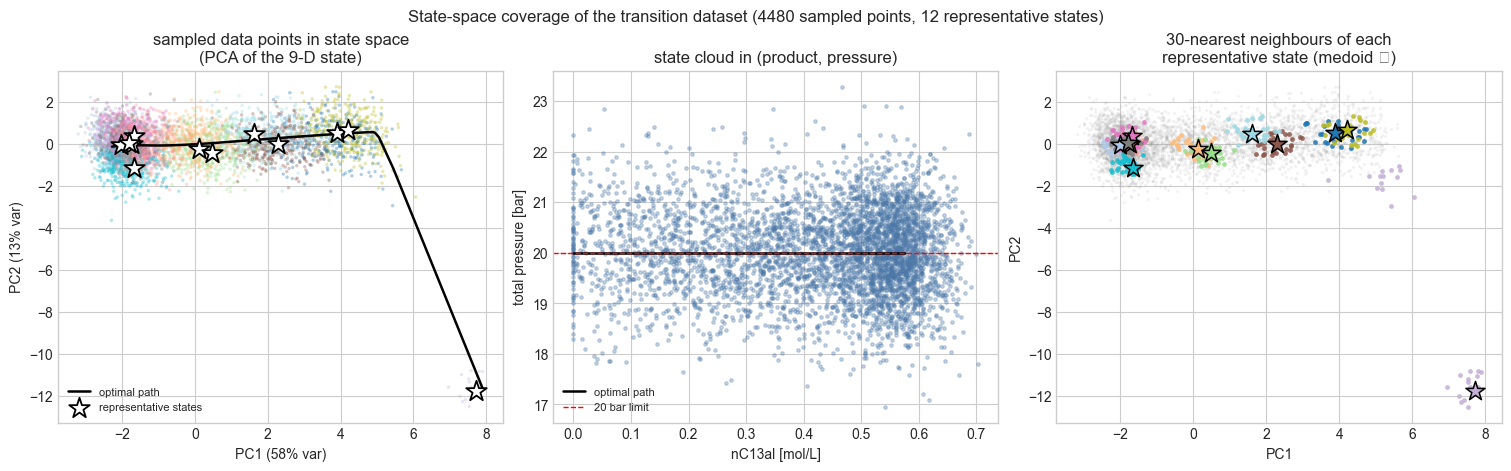

4480 state samples | 12 representative states (KMeans medoids) | 30-NN neighbourhoods | PCA variance captured 70.9%


In [7]:
# === state-space coverage + k-nearest-neighbour representative states ==
# Standardise the 9-D sampled states, then 2-D PCA purely for visualisation.
scaler = StandardScaler().fit(samp_states)
S = scaler.transform(samp_states)
pca = PCA(n_components=2, random_state=0).fit(S)
P = pca.transform(S)
opt_P = pca.transform(scaler.transform(opt_states))

# Representative states: KMeans finds K centroids; each centroid is snapped to the
# nearest REAL sampled state (its medoid) with a 1-nearest-neighbour query, and a
# k-NN query then pulls the K_NN closest data points around each representative.
K_REP, K_NN = 12, 30
km = KMeans(n_clusters=K_REP, n_init=10, random_state=0).fit(S)
labels = km.labels_
_, medoid_idx = NearestNeighbors(n_neighbors=1).fit(S).kneighbors(km.cluster_centers_)
medoid_idx = medoid_idx.ravel()
rep_states = samp_states[medoid_idx]                          # representative states (orig units)
_, nbr_idx = NearestNeighbors(n_neighbors=K_NN).fit(S).kneighbors(S[medoid_idx])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)

# (1) PCA cloud of all sampled states, coloured by cluster, optimal path overlaid
ax[0].scatter(P[:, 0], P[:, 1], c=labels, cmap="tab20", s=6, alpha=0.35, linewidths=0)
ax[0].plot(opt_P[:, 0], opt_P[:, 1], color="k", lw=1.8, label="optimal path")
ax[0].scatter(P[medoid_idx, 0], P[medoid_idx, 1], marker="*", s=240, c="white",
              edgecolors="k", linewidths=1.3, zorder=5, label="representative states")
ax[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% var)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% var)",
          title="sampled data points in state space\n(PCA of the 9-D state)")
ax[0].legend(frameon=False, fontsize=8, loc="best")

# (2) physically meaningful projection: the constraint coordinate (product, pressure)
p_tot_in = samp_states[:, P_H2] + samp_states[:, P_CO]
ax[1].scatter(samp_states[:, PROD], p_tot_in, s=6, alpha=0.30, color="#4c78a8")
ax[1].plot(opt_states[:, PROD], opt_states[:, P_H2] + opt_states[:, P_CO],
           color="k", lw=1.8, label="optimal path")
ax[1].axhline(MAX_P, ls="--", color="r", lw=1, label="20 bar limit")
ax[1].set(xlabel="nC13al [mol/L]", ylabel="total pressure [bar]",
          title="state cloud in (product, pressure)")
ax[1].legend(frameon=False, fontsize=8)

# (3) k-nearest-neighbour neighbourhoods of each representative state
ax[2].scatter(P[:, 0], P[:, 1], s=5, alpha=0.12, color="#999999", linewidths=0)
rep_colors = plt.cm.tab20(np.linspace(0, 1, K_REP))
for r in range(K_REP):
    ax[2].scatter(P[nbr_idx[r], 0], P[nbr_idx[r], 1], s=12, color=rep_colors[r],
                  alpha=0.85, linewidths=0)
    ax[2].scatter(P[medoid_idx[r], 0], P[medoid_idx[r], 1], marker="*", s=210,
                  color=rep_colors[r], edgecolors="k", linewidths=1.1, zorder=5)
ax[2].set(xlabel="PC1", ylabel="PC2",
          title=f"{K_NN}-nearest neighbours of each\nrepresentative state (medoid ★)")

fig.suptitle(f"State-space coverage of the transition dataset "
             f"({len(samp_states)} sampled points, {K_REP} representative states)")
plt.show()

print(f"{len(samp_states)} state samples | {K_REP} representative states (KMeans medoids) | "
      f"{K_NN}-NN neighbourhoods | PCA variance captured "
      f"{pca.explained_variance_ratio_[:2].sum()*100:.1f}%")


## Three surrogates, trained with the source code

Each surrogate maps the **11 inputs** `[state(9), T, u]` to the **3 outputs**
`[p_H2', p_CO', Δ nC13al]`.

| surrogate | training call | hidden activation | embedding (for Gurobi) |
|---|---|---|---|
| **tanh net** | `PWLNet.train(activation="tanh")` | smooth tanh | PWL-tanh big-M, **13-segment** (approximates the smooth tanh) |
| **ReLU net** | `PWLNet.train(activation="relu")` | ReLU | ReLU big-M (OMLT) — *exactly* a MILP |
| **PWL net** | `PWLNet.train(activation="tanh")` + 13-segment PWL activation | piecewise-linear tanh | PWL-tanh big-M, **13-segment** — *exact* (prediction == embedding) |

All three reduce to MILPs for Gurobi. The **PWL net** is a tanh network whose nonlinearity
is evaluated through the **exact 13-segment PWL interpolant of `tanh`** (dense near 0, where
the standard 5-piece set is too coarse and leaves a large pressure gap), so what we train and
score is *identical* to what the MILP optimizes — no smooth-vs-PWL gap. The tanh net keeps a
small approximation gap and ReLU is exact by construction.


In [8]:
# === USAGE: train the three surrogates with the source API ============
HID = 16
# 13-segment PWL-tanh breakpoints, deliberately DENSE near 0 where tanh curves most.
# The standard 5/7-piece SOSX sets are too coarse near the origin and leave a ~1.5 bar
# gap on the next-pressure target; this finer set matches the smooth tanh net closely.
BP = np.array([-4.0, -3.0, -2.0, -1.5, -1.0, -0.6, -0.3, 0.3, 0.6, 1.0, 1.5, 2.0, 3.0, 4.0])
BP_TANH = BP_PWL = BP
N_BP = len(BP) - 1                # number of PWL segments (for display)
EPOCHS = 500   # training-duration knob (more epochs -> longer training, not capped)
train_seconds = {}
histories = {}   # per-epoch train/val loss curves from each Keras fit

t0 = time.perf_counter()
tanh_fit = PWLNet.train(Xtr, Ytr, hidden_layers=[HID], activation="tanh",
                        epochs=EPOCHS, batch_size=64, learning_rate=1e-3,
                        random_seed=1, validation_data=(Xva, Yva))
tanh_net = tanh_fit.network
histories["tanh"] = tanh_fit.trainer.history_
train_seconds["tanh"] = time.perf_counter() - t0

t0 = time.perf_counter()
relu_fit = PWLNet.train(Xtr, Ytr, hidden_layers=[HID], activation="relu",
                        epochs=EPOCHS, batch_size=64, learning_rate=1e-3,
                        random_seed=1, validation_data=(Xva, Yva))
relu_net = relu_fit.network
histories["relu"] = relu_fit.trainer.history_
train_seconds["relu"] = time.perf_counter() - t0

# the PWL net is a (compact) tanh net whose activation IS the 13-segment PWL tanh
t0 = time.perf_counter()
pwl_fit = PWLNet.train(Xtr, Ytr, hidden_layers=[HID], activation="tanh",
                       epochs=EPOCHS, batch_size=64, learning_rate=1e-3,
                       random_seed=1, validation_data=(Xva, Yva))
pwl_net = pwl_fit.network
histories["pwl"] = pwl_fit.trainer.history_
train_seconds["pwl"] = time.perf_counter() - t0

# exact PWL-tanh forward map -- matches build_tanh_pwl_bigm_block(breakpoints=BP_PWL)
_BP = get_tanh_breakpoints(BP_PWL); _BPY = np.tanh(_BP)
def pwl_predict(net, Xin):
    'Evaluate a tanh net with tanh replaced by its 13-segment PWL interpolant.'
    Xs = net.input_scaler.transform(Xin) if net.input_scaler is not None else np.asarray(Xin, float)
    h = Xs
    for layer in net.layers[:-1]:
        z = h @ layer.weights + layer.biases
        h = np.interp(z.ravel(), _BP, _BPY).reshape(z.shape)
    out = net.layers[-1]
    ys = h @ out.weights + out.biases
    return net.output_scaler.inverse_transform(ys) if net.output_scaler is not None else ys

print("training times [s]:", {k: round(v, 1) for k, v in train_seconds.items()})

training times [s]: {'tanh': 68.3, 'relu': 51.1, 'pwl': 51.1}


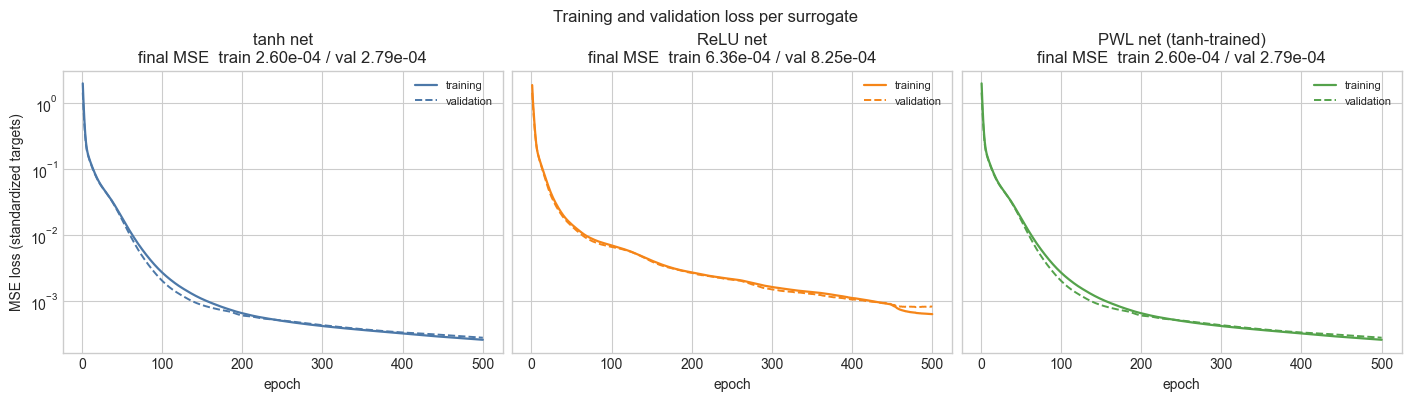

In [9]:
# === training / validation loss curves for each surrogate ============
# Each Keras fit logged per-epoch MSE; plot train vs. val for all three nets.
titles = {"tanh": "tanh net", "relu": "ReLU net", "pwl": "PWL net (tanh-trained)"}
cmap_loss = {"tanh": "#4c78a8", "relu": "#f58518", "pwl": "#54a24b"}

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True, constrained_layout=True)
for a, key in zip(ax, ["tanh", "relu", "pwl"]):
    h = histories[key]
    epochs = np.arange(1, len(h["loss"]) + 1)
    a.plot(epochs, h["loss"], color=cmap_loss[key], lw=1.6, label="training")
    if "val_loss" in h:
        a.plot(epochs, h["val_loss"], color=cmap_loss[key], lw=1.4, ls="--", label="validation")
    final_tr = h["loss"][-1]
    final_va = h["val_loss"][-1] if "val_loss" in h else np.nan
    a.set(xlabel="epoch", title=f"{titles[key]}\nfinal MSE  train {final_tr:.2e} / val {final_va:.2e}")
    a.set_yscale("log")
    a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel("MSE loss (standardized targets)")
fig.suptitle("Training and validation loss per surrogate")
plt.show()

In [10]:
# === structures and training parameters, side by side =================
def n_params(net):
    return int(sum(l.weights.size + l.biases.size for l in net.layers))

structure = pd.DataFrame({
    "tanh net":  ["smooth tanh", f"[{HID}]", N_IN, N_OUT, n_params(tanh_net),
                  "MSE / Adam", str(EPOCHS), "PWL-tanh big-M", f"{N_BP}-segment (approx)", "Gurobi", train_seconds["tanh"]],
    "ReLU net":  ["relu", f"[{HID}]", N_IN, N_OUT, n_params(relu_net),
                  "MSE / Adam", str(EPOCHS), "ReLU big-M (OMLT)", "exact", "Gurobi", train_seconds["relu"]],
    "PWL net":   ["PWL tanh (13-seg)", f"[{HID}]", N_IN, N_OUT, n_params(pwl_net),
                  "MSE / Adam", str(EPOCHS), "PWL-tanh big-M", f"{N_BP}-segment (exact)", "Gurobi", train_seconds["pwl"]],
}, index=["hidden activation", "hidden layers", "inputs (state+T+u)", "outputs (p_H2', p_CO', Δprod)", "trainable params",
          "loss / optimizer", "epochs", "embedding", "PWL resolution", "MILP solver", "training time (s)"])
structure


,tanh net,ReLU net,PWL net
hidden activation,smooth tanh,relu,PWL tanh (13-seg)
hidden layers,[16],[16],[16]
inputs (state+T+u),11,11,11
"outputs (p_H2', p_CO', Δprod)",3,3,3
trainable params,243,243,243
loss / optimizer,MSE / Adam,MSE / Adam,MSE / Adam
epochs,500,500,500
embedding,PWL-tanh big-M,ReLU big-M (OMLT),PWL-tanh big-M
PWL resolution,13-segment (approx),exact,13-segment (exact)
MILP solver,Gurobi,Gurobi,Gurobi


,tanh net,ReLU net,PWL net
sMAE train,0.0101,0.0134,0.0187
P_next MAE train [bar],0.0673,0.0433,0.1587
Δprod MAE train,0.0000,0.0001,0.0000
sMAE val,0.0105,0.0149,0.0187
P_next MAE val [bar],0.0725,0.0436,0.1617
Δprod MAE val,0.0000,0.0001,0.0000
sMAE test,0.0105,0.0144,0.0189
P_next MAE test [bar],0.0689,0.0430,0.1606
Δprod MAE test,0.0000,0.0001,0.0000
training time [s],68.3390,51.1277,51.1212


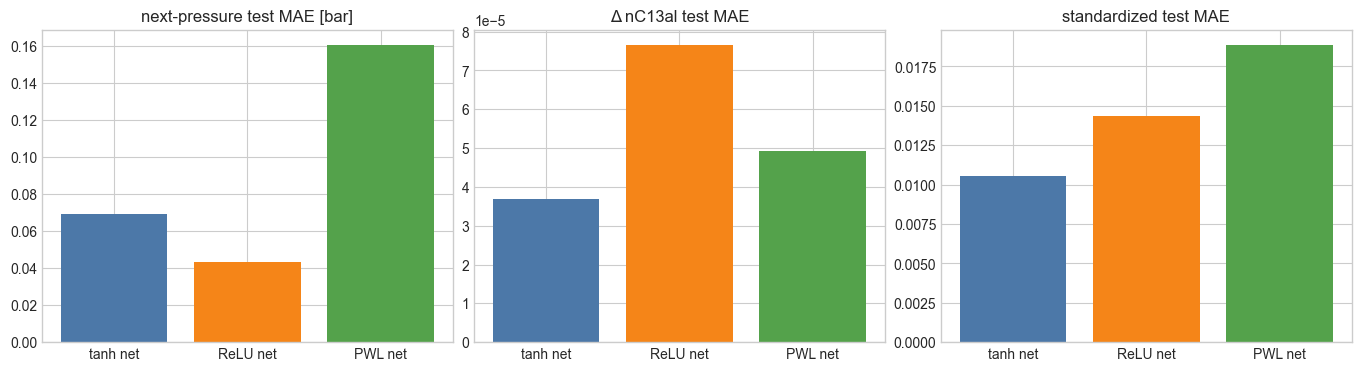

In [11]:
# === accuracy on train / val / test ===================================
# Targets are [p_H2', p_CO', Δ nC13al]; the two quantities that matter for control are
# the NEXT TOTAL PRESSURE (col0+col1, drives the 20-bar constraint) and Δ nC13al (col2,
# drives the objective). The PWL net is scored through its exact PWL forward map.
y_sd = Ytr.std(axis=0) + 1e-9   # per-output std for a scale-free aggregate error

def errors(predict_fn):
    row = {}
    for split, (Xs, Ys) in [("train", (Xtr, Ytr)), ("val", (Xva, Yva)), ("test", (Xte, Yte))]:
        pred = predict_fn(Xs)
        err = np.abs(pred - Ys)
        p_next_err = np.abs((pred[:, 0] + pred[:, 1]) - (Ys[:, 0] + Ys[:, 1]))
        row[f"sMAE {split}"] = float(np.mean(err / y_sd))
        row[f"P_next MAE {split} [bar]"] = float(np.mean(p_next_err))
        row[f"Δprod MAE {split}"] = float(np.mean(err[:, 2]))
    return row

acc = pd.DataFrame({
    "tanh net": errors(tanh_net.predict),
    "ReLU net": errors(relu_net.predict),
    "PWL net":  errors(lambda Z: pwl_predict(pwl_net, Z)),
})
acc.loc["training time [s]"] = [train_seconds["tanh"], train_seconds["relu"], train_seconds["pwl"]]
display(acc.round(4))

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6), constrained_layout=True)
names = ["tanh net", "ReLU net", "PWL net"]
colors = ["#4c78a8", "#f58518", "#54a24b"]
for a, metric, ttl in zip(ax, ["P_next MAE test [bar]", "Δprod MAE test", "sMAE test"],
                          ["next-pressure test MAE [bar]", "Δ nC13al test MAE", "standardized test MAE"]):
    a.bar(names, [acc.loc[metric, n] for n in names], color=colors)
    a.set_title(ttl)
plt.show()


## Embedding the surrogates and the greedy solver

We tighten every network's input box to the *reachable* region of the data and wrap the
three embeddings behind a single `build_block` helper. Each surrogate outputs
`[p_H2', p_CO', Δ nC13al]`, so the controller:

* enforces the pressure constraint on the **predicted next total pressure**
  `p_H2' + p_CO' ≤ 20 bar`, and
* maximises the **predicted next product** `nC13al + Δ nC13al`.

**Greedy (one-step) control.** At each 15-second step we solve a *single-block* MILP for
the `(T, u)` that maximise the next-step `nC13al` subject to the predicted pressure / box
constraints, apply it to the **true** plant, advance one step, and re-solve. The pressure
limit is imposed softly through a heavily-penalised slack so the MILP is always feasible;
the slack is zero whenever the limit can be met.


In [12]:
# === USAGE: tighten embedding bounds + block/solver helpers ===========
def reachable_bounds(Xdata, *, margin_frac=0.10):
    'Tight per-input box [state(9), T, u] from the training inputs.'
    lo = Xdata.min(axis=0).astype(float)
    hi = Xdata.max(axis=0).astype(float)
    pad = margin_frac * (hi - lo) + 1e-6
    lo, hi = lo - pad, hi + pad
    lo[nS], hi[nS] = T_LO, T_HI          # temperature column -> control bounds
    lo[nS + 1], hi[nS + 1] = U_LO, U_HI  # gas-feed column   -> control bounds
    return list(zip(lo.tolist(), hi.tolist())), lo[:nS], hi[:nS]

input_bounds, state_lo, state_hi = reachable_bounds(X)   # tight box from the data
tanh_e = tighten_network_bounds(tanh_net, input_bounds)
relu_e = tighten_network_bounds(relu_net, input_bounds)
pwl_e  = tighten_network_bounds(pwl_net,  input_bounds)

# (embedding-kind, network, PWL breakpoints) for each surrogate
EMBED = {
    "tanh": ("pwl",  tanh_e, BP_TANH),
    "relu": ("relu", relu_e, None),
    "pwl":  ("pwl",  pwl_e,  BP_PWL),
}
PEN = 1.0e3   # exact-penalty weight on the soft 20-bar slack

def build_block(model, kind, net, bp, name):
    'PWL-tanh or ReLU big-M block; outputs are [p_H2\', p_CO\', Δ nC13al] in original units.'
    if kind == "relu":
        _, b = build_omlt_block(net, "relu_bigm", model=model, block_name=name)
        return b
    return build_tanh_pwl_bigm_block(model, net, block_name=name, breakpoints=bp)

def _clipx(x):
    return np.clip(x, state_lo, state_hi)


In [13]:
# === USAGE: greedy one-step MILP move (Gurobi) ========================
# inputs = [state(9), T, u]; outputs = [p_H2', p_CO', Δ nC13al].
def greedy_move(kind, net, bp, x, solver):
    m = pyo.ConcreteModel()
    b = build_block(m, kind, net, bp, "step")
    xc = _clipx(x)
    for s in range(nS):
        b.inputs[s].fix(float(xc[s]))               # current measured state
    Tin, uin = b.inputs[nS], b.inputs[nS + 1]       # free decisions T, u (box bounds)
    p_next = b.outputs[0] + b.outputs[1]            # predicted next total pressure
    nC13al_next = xc[PROD] + b.outputs[2]           # current product + predicted change
    m.sp = pyo.Var(bounds=(0, None))                # soft 20-bar slack
    m.pcon = pyo.Constraint(expr=p_next <= MAX_P + m.sp)
    m.obj = pyo.Objective(expr=-nC13al_next + PEN * m.sp)   # maximise next product
    t0 = time.perf_counter(); solver.solve(m, tee=False); dt = time.perf_counter() - t0
    return float(np.clip(pyo.value(Tin), T_LO, T_HI)), float(np.clip(pyo.value(uin), U_LO, U_HI)), dt

def run_greedy(kind, net, bp, n_steps, plant):
    solver = get_milp_solver("gurobi", options={"OutputFlag": 0, "MIPGap": 0.01})
    x = INITIAL_STATE.astype(float).copy()
    states, ctrls, total = [x.copy()], [], 0.0
    for k in range(n_steps):
        T, u, dt = greedy_move(kind, net, bp, x, solver)
        x = step_state(x, T, u, DT, plant)          # roll the TRUE plant forward one step
        states.append(x.copy()); ctrls.append([T, u]); total += dt
    return dict(states=np.asarray(states), controls=np.asarray(ctrls), solve_time=total)


## Greedy control over a 10-minute horizon

`SHORT_CONTROL_HORIZON_MIN` is the control horizon (**10 minutes**, i.e. **40** decisions
at `DT = 15 s`). For each surrogate we solve one MILP per step, apply it to the true
(nominal) plant, and re-solve. The table reports the total Gurobi solve time; the plots
compare temperature, feed, pressure and the realised `nC13al` against the certified
optimum.

> **Read the `max pressure` column carefully.** The 20-bar limit is enforced on the
> surrogate's *predicted* next pressure `p_H2' + p_CO'`. A myopic one-step controller
> still pushes the feed to where its surrogate thinks the limit binds, so an inaccurate
> surrogate can let the **true** plant overshoot — which is exactly why the next-pressure
> accuracy of the surrogate (scored above) matters for constraint satisfaction.


In [14]:
SHORT_CONTROL_HORIZON_MIN = 10.0                 # greedy control horizon [min]
H10 = int(round(SHORT_CONTROL_HORIZON_MIN / DT)) # = 40 decisions at 15 s

plant_nom = HydroformylationParameters()         # nominal catalyst (gamma = 1)
greedy10 = {name: run_greedy(kind, net, bp, H10, plant_nom)
            for name, (kind, net, bp) in EMBED.items()}

tbl = pd.DataFrame({
    "formulation": ["tanh (PWL-13 big-M)", "ReLU (big-M)", "PWL (exact 13 big-M)"],
    "solve time [s]": [greedy10[k]["solve_time"] for k in EMBED],
    "avg per move [ms]": [1000 * greedy10[k]["solve_time"] / H10 for k in EMBED],
    "terminal nC13al": [greedy10[k]["states"][-1, PROD] for k in EMBED],
    "max pressure [bar]": [(greedy10[k]["states"][:, P_H2] + greedy10[k]["states"][:, P_CO]).max() for k in EMBED],
}, index=list(EMBED))
print(f"{SHORT_CONTROL_HORIZON_MIN:g}-minute greedy NMPC - Gurobi solve times")
tbl.round(4)


10-minute greedy NMPC - Gurobi solve times


,formulation,solve time [s],avg per move [ms],terminal nC13al,max pressure [bar]
tanh,tanh (PWL-13 big-M),3.6555,91.3863,0.4399,20.0000
relu,ReLU (big-M),1.0200,25.5006,0.4341,20.0837
pwl,PWL (exact 13 big-M),2.9287,73.2184,0.4399,20.0000


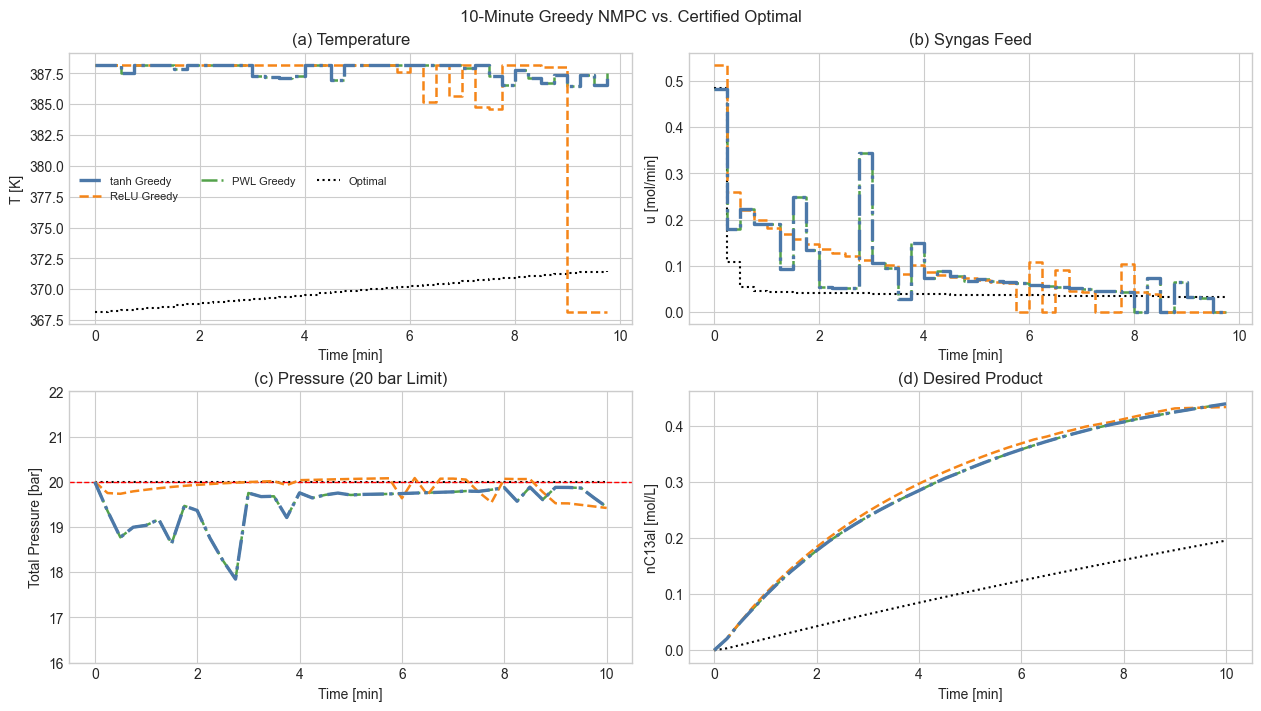

In [15]:
def plot_runs(runs, n_steps, title, ncol_leg=3, save_stem=None):
    tc = np.arange(n_steps) * DT
    tg = np.arange(n_steps + 1) * DT
    cmap = {"tanh": "#4c78a8", "relu": "#f58518", "pwl": "#54a24b"}
    labels = {"tanh": "tanh Greedy", "relu": "ReLU Greedy", "pwl": "PWL Greedy"}
    styles = {
        "tanh": {"ls": "-.",  "lw": 2.4, "zorder": 5},
        "relu": {"ls": "--", "lw": 1.8, "zorder": 4},
        "pwl":  {"ls": "-.", "lw": 1.8, "zorder": 3},
    }
    fig, ax = plt.subplots(2, 2, figsize=(12.5, 7), constrained_layout=True)
    for k, r in runs.items():
        st, ct = r["states"], r["controls"]
        p = st[:, IDX["p_H2"]] + st[:, IDX["p_CO"]]
        style = styles[k]
        label = labels[k]
        ax[0, 0].step(tc, ct[:, 0], where="post", color=cmap[k], label=label, **style)
        ax[0, 1].step(tc, ct[:, 1], where="post", color=cmap[k], label=label, **style)
        ax[1, 0].plot(tg, p, color=cmap[k], label=label, **style)
        ax[1, 1].plot(tg, st[:, IDX["nC13al"]], color=cmap[k], label=label, **style)
    w = n_steps
    ax[0, 0].step(tc, T_star[:w], where="post", color="k", ls=":", label="Optimal")
    ax[0, 1].step(tc, u_star[:w], where="post", color="k", ls=":", label="Optimal")
    ax[1, 0].plot(opt_times[:w + 1], opt_p[:w + 1], color="k", ls=":", label="Optimal")
    ax[1, 0].axhline(MAX_P, color="r", ls="--", lw=1)
    ax[1, 1].plot(opt_times[:w + 1], opt_states[:w + 1, IDX["nC13al"]], color="k", ls=":", label="Optimal")
    ax[0, 0].set(ylabel="T [K]", xlabel="Time [min]", title="(a) Temperature")
    ax[0, 1].set(ylabel="u [mol/min]", xlabel="Time [min]", title="(b) Syngas Feed")
    ax[1, 0].set(ylabel="Total Pressure [bar]", xlabel="Time [min]", title="(c) Pressure (20 bar Limit)")
    ax[1, 1].set(ylabel="nC13al [mol/L]", xlabel="Time [min]", title="(d) Desired Product")
    # keep the 20-bar region readable: cap the axis near the limit (not the runs),
    # and annotate any run whose true-plant pressure runs off-axis (open-loop MS plans
    # on an inaccurate surrogate can diverge even when the surrogate thinks they are safe)
    pmax_all = {k: float((r["states"][:, IDX["p_H2"]] + r["states"][:, IDX["p_CO"]]).max()) for k, r in runs.items()}
    cap = max(MAX_P * 2.2, 1.1 * float(opt_p[:w + 1].max()))
    ax[1, 0].set_ylim(16,22)
    over = [f"{k} {v:.0f}" for k, v in pmax_all.items() if v > cap]
    if over:
        ax[1, 0].text(0.02, 0.96, "off-axis max [bar]: " + ", ".join(over),
                      transform=ax[1, 0].transAxes, va="top", fontsize=7, color="#333333")
    ax[0, 0].legend(frameon=False, ncol=ncol_leg, fontsize=8)
    fig.suptitle(title)
    if save_stem is not None:
        from pathlib import Path
        fig_dir = Path.cwd().parent / "images" / "article"
        fig_dir.mkdir(parents=True, exist_ok=True)
        for ext in ("pdf", "png"):
            fig.savefig(fig_dir / f"{save_stem}.{ext}", bbox_inches="tight", dpi=300)
        print(f"saved {fig_dir / save_stem}.pdf (+ .png)")
    plt.show()

plot_runs(greedy10, H10, f"{SHORT_CONTROL_HORIZON_MIN:g}-Minute Greedy NMPC vs. Certified Optimal")


## Greedy control over the full 70-minute horizon

The same greedy loop now runs over the **entire 70-minute batch** (**280** 15-second
decisions) for each surrogate against the nominal plant, and is compared to the certified
optimum. Each step still solves a single-block MILP for the `(T, u)` maximising the
predicted next `nC13al` subject to the predicted 20-bar pressure limit.

Because the controller is myopic, the realised pressure is only constrained through the
surrogate's *predicted* `p_H2' + p_CO'`, so the `max pressure` column again exposes how an
imperfect next-pressure estimate lets the **true** plant drift past 20 bar over the long
horizon.


In [16]:
H70 = len(u_star)    # 280 steps = the full 70-minute batch
greedy70 = {name: run_greedy(kind, net, bp, H70, plant_nom)
            for name, (kind, net, bp) in EMBED.items()}

tbl70 = pd.DataFrame({
    "formulation": ["tanh (PWL-13 big-M)", "ReLU (big-M)", "PWL (exact 13 big-M)"],
    "total solve [s]": [greedy70[k]["solve_time"] for k in EMBED],
    "avg per move [ms]": [1000 * greedy70[k]["solve_time"] / H70 for k in EMBED],
    "terminal nC13al": [greedy70[k]["states"][-1, PROD] for k in EMBED],
    "max pressure [bar]": [(greedy70[k]["states"][:, P_H2] + greedy70[k]["states"][:, P_CO]).max() for k in EMBED],
}, index=list(EMBED))
tbl70.loc["optimal"] = ["multiple-shooting (true ODE)", np.nan, np.nan, OPT_TERMINAL, float(opt_p.max())]
print("70-minute greedy NMPC vs. certified optimal")
tbl70.round(4)


70-minute greedy NMPC vs. certified optimal


,formulation,total solve [s],avg per move [ms],terminal nC13al,max pressure [bar]
tanh,tanh (PWL-13 big-M),20.6011,73.5753,0.5467,20.0000
relu,ReLU (big-M),6.8104,24.3230,0.5158,20.0837
pwl,PWL (exact 13 big-M),23.2858,83.1636,0.5467,20.0000
optimal,multiple-shooting (true ODE),NaN,NaN,0.5755,20.0000


saved c:\Users\Sunoy\University\PY_M_projects\PWLNet\images\article\hydro_greedy_70min.pdf (+ .png)


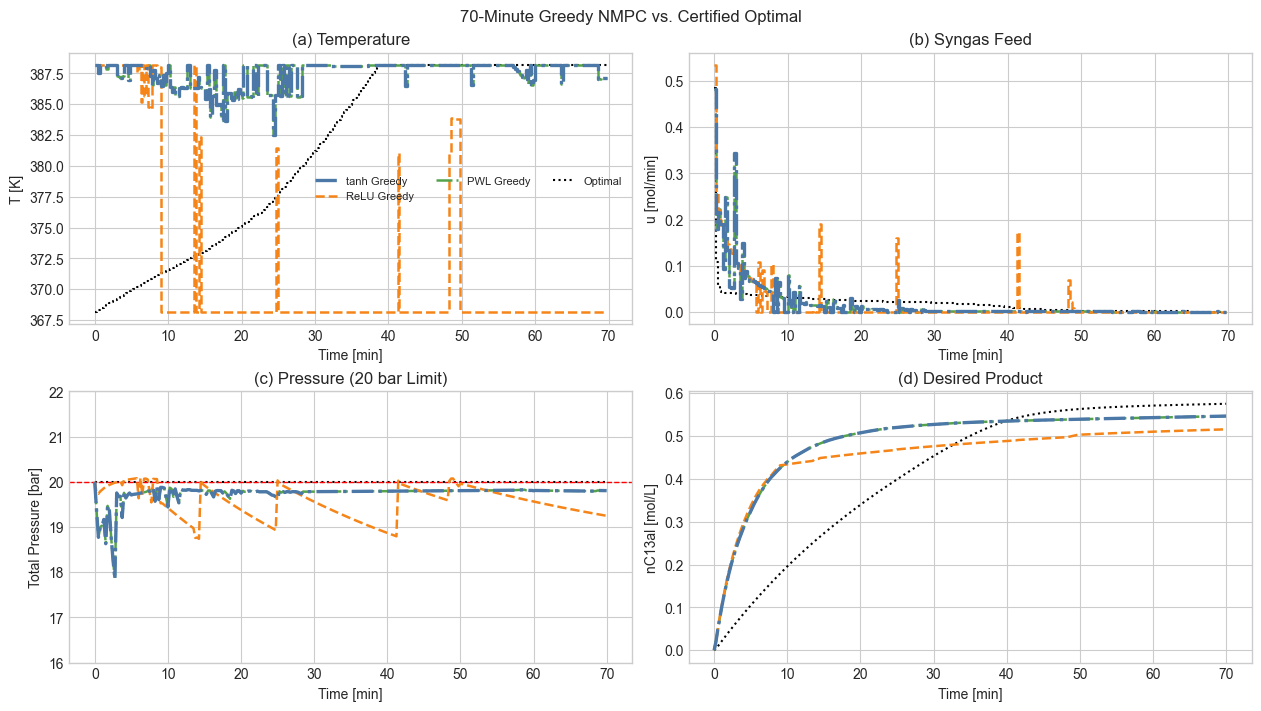

In [17]:
plot_runs(greedy70, H70, "70-Minute Greedy NMPC vs. Certified Optimal", save_stem="hydro_greedy_70min")


## Summary

* The **known optimal** (pressure held on the 20 bar constraint; temperature ramping
  368.15 K -> 388.15 K, saturating at ~38.75 min) is loaded from
  `datasets/ms_15s_optimal.npz`. We do **not** recompute it.
* Training data is a **state-space transition dataset**: every optimal state is used as an
  anchor, the **data points are scattered around it in the state space**, and one true
  stiff-ODE step is taken from each sampled `(state, T, u)`. The **catalyst activation rate
  is held at its nominal value** — no catalyst drift in data creation.
* The surrogate targets are exactly what the controller needs — the **resulting partial
  pressures next step** `(p_H2', p_CO')` for the 20-bar constraint and the **change of the
  desired compound** `Δ nC13al` for the objective. The plant is autonomous, so **time is
  not a feature**: the map is `(state(9), T, u) → (p_H2', p_CO', Δ nC13al)`.
* The dataset's **state-space coverage** is visualised with PCA, and a
  **k-nearest-neighbour** view highlights representative states (KMeans medoids) and the
  neighbours that surround each.
* All three surrogates — **tanh**, **ReLU** and an **exact 13-segment PWL** net — embed as
  **MILPs solved by Gurobi**. The PWL breakpoints are deliberately **dense near 0** so the
  embedded next-pressure error stays close to the smooth net. Accuracy is reported as
  **next-pressure MAE** (constraint fidelity) and **Δ nC13al MAE** (objective fidelity).
* The **greedy** controller is run over both a **10-minute** horizon (40 decisions) and the
  **full 70-minute** batch (280 decisions): at each 15-second step it maximises the predicted
  next product subject to the predicted 20-bar pressure limit, applies the move to the true
  plant, and re-solves. Because it is myopic, the realised pressure can drift slightly past
  20 bar when the surrogate's next-pressure estimate is imperfect. (The multiple-shooting and
  catalyst-scenario studies were intentionally dropped to keep the run short.)
